# Task 5 — Unsupervised model baselines, Round 1

Load the two saved datasets, fit detector families, and compare alert stability and behavior. The instructor permits unsupervised fitting on Task 5 Test. Without labels, no offline F₃ or best fraud detector can be identified.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
SRC = ROOT / "src"
from src.pipeline.random_seed import set_seed
SEED = set_seed()
import json, joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.mixture import GaussianMixture
from src.task5.anomaly_models import BinaryAnomalyModel, PCAReconstruction, EmpiricalTail
from src.pipeline.save_model import save_model
from src.pipeline.evaluate_model import evaluate_model
from src.pipeline.read_evalutate_summarize import read_evaluation_index

def load_dataset(name):
    card = json.loads((SRC / "task5" / "data" / "eda" / f"{name}.json").read_text(encoding="utf-8"))
    assert "train" not in card["splits"] and "test" in card["splits"]
    path = SRC / card["splits"]["test"]["path"]
    frame = pd.read_parquet(path) if card["format"] == "parquet" else pd.read_csv(path)
    assert frame.player_id.is_unique and "is_anomaly" not in frame
    return frame.drop(columns="player_id"), frame.player_id

datasets = {"original": ("eda_original_v1", *load_dataset("eda_original_v1")),
            "engineered": ("eda_1_v1", *load_dataset("eda_1_v1"))}
assert datasets["original"][2].equals(datasets["engineered"][2])
print({key: data[1].shape for key, data in datasets.items()})

{'original': (25889, 122), 'engineered': (25889, 213)}


## Common split and diagnostic

Fit on 12,000 rows; use 4,000 held-out rows to compare top-5% alert stability. The alternate fit overlaps the first fit, so this measures sensitivity to a smaller training sample, not detection quality.

In [2]:
rows = np.arange(len(datasets["original"][1]))
dev_idx, hold_idx = train_test_split(rows, train_size=12000, test_size=4000, random_state=SEED)
dev_b_idx = np.random.default_rng(SEED).choice(dev_idx, size=10000, replace=False)
X_dev = {key: data[1].iloc[dev_idx] for key, data in datasets.items()}
X_dev_b = {key: data[1].iloc[dev_b_idx] for key, data in datasets.items()}
X_hold = {key: data[1].iloc[hold_idx] for key, data in datasets.items()}

def top_overlap(a, b, fraction=.05):
    k = max(1, int(round(len(a)*fraction)))
    top_a = set(np.argpartition(a, -k)[-k:])
    top_b = set(np.argpartition(b, -k)[-k:])
    return len(top_a & top_b) / len(top_a | top_b)

### Save each baseline

A complete saved result is reused on cell reruns. Change its name when changing a model or dataset.

In [3]:
from sklearn.base import clone
SAVE_DIR = SRC / "task5" / "save"
EXPERIMENTS = []

def saved_result(name, dataset):
    model_path = SAVE_DIR / f"{name}.joblib"
    card_path = SAVE_DIR / f"{name}.json"
    eval_path = SAVE_DIR / f"{name}-evaluation.json"
    present = [path.exists() for path in (model_path, card_path, eval_path)]
    if any(present) and not all(present):
        raise RuntimeError(f"Partial artifact for {name}; inspect before rerunning")
    if not all(present):
        return None
    card = json.loads(card_path.read_text(encoding="utf-8"))
    evaluation = json.loads(eval_path.read_text(encoding="utf-8"))
    if card["data_name"] != datasets[dataset][0] or evaluation["metric"] != "top5_rank_stability_jaccard":
        raise ValueError(f"Artifact lineage or metric mismatch for {name}")
    return evaluation

def record_model(name, dataset, model, description):
    alternate = clone(model).fit(X_dev_b[dataset])
    stability = top_overlap(model.anomaly_score(X_hold[dataset]),
                            alternate.anomaly_score(X_hold[dataset]))
    save_model(task=5, name=name, model=model, data_name=datasets[dataset][0],
               card={"idea": description, "seed": SEED, "fit_rows": len(X_dev[dataset]),
                     "alert_budget": .05, "scope": "user-directed unsupervised fit on Task 5 Test"})
    evaluate_model(task=5, name=name,
                   card={"meaning": "top-5%-rank Jaccard across overlapping development fits on 4000-row holdout; not F3",
                         "seed": SEED},
                   score=stability, metric_name="top5_rank_stability_jaccard",
                   higher_is_better=True)
    print(name, "rank stability:", round(stability, 4))

## Detector baselines

Each original/engineered pair uses the same rows and alert budget.

### 1. Isolation Forest

In [4]:
name = "t5_r1_iforest_original_v1"
EXPERIMENTS.append((name, "original", "iforest"))
if saved_result(name, "original") is None:
    model = BinaryAnomalyModel(IsolationForest(n_estimators=160, max_samples=256, random_state=SEED, n_jobs=-1), anomaly_fraction=.05)
    model.fit(X_dev["original"])
    record_model(name, "original", model, "Isolation Forest, 256-row subsamples")

In [5]:
name = "t5_r1_iforest_engineered_v1"
EXPERIMENTS.append((name, "engineered", "iforest"))
if saved_result(name, "engineered") is None:
    model = BinaryAnomalyModel(IsolationForest(n_estimators=160, max_samples=256, random_state=SEED, n_jobs=-1), anomaly_fraction=.05)
    model.fit(X_dev["engineered"])
    record_model(name, "engineered", model, "Isolation Forest, 256-row subsamples")

### 2. Local Outlier Factor

In [6]:
name = "t5_r1_lof_original_v1"
EXPERIMENTS.append((name, "original", "lof"))
if saved_result(name, "original") is None:
    model = BinaryAnomalyModel(LocalOutlierFactor(n_neighbors=35, novelty=True, n_jobs=-1), anomaly_fraction=.05)
    model.fit(X_dev["original"])
    record_model(name, "original", model, "Local Outlier Factor, 35 neighbors")

In [7]:
name = "t5_r1_lof_engineered_v1"
EXPERIMENTS.append((name, "engineered", "lof"))
if saved_result(name, "engineered") is None:
    model = BinaryAnomalyModel(LocalOutlierFactor(n_neighbors=35, novelty=True, n_jobs=-1), anomaly_fraction=.05)
    model.fit(X_dev["engineered"])
    record_model(name, "engineered", model, "Local Outlier Factor, 35 neighbors")

### 3. One-Class SVM

In [8]:
name = "t5_r1_ocsvm_original_v1"
EXPERIMENTS.append((name, "original", "ocsvm"))
if saved_result(name, "original") is None:
    model = BinaryAnomalyModel(OneClassSVM(kernel="rbf", nu=.05, gamma="scale", cache_size=500), anomaly_fraction=.05)
    model.fit(X_dev["original"])
    record_model(name, "original", model, "RBF One-Class SVM, nu 0.05")

In [9]:
name = "t5_r1_ocsvm_engineered_v1"
EXPERIMENTS.append((name, "engineered", "ocsvm"))
if saved_result(name, "engineered") is None:
    model = BinaryAnomalyModel(OneClassSVM(kernel="rbf", nu=.05, gamma="scale", cache_size=500), anomaly_fraction=.05)
    model.fit(X_dev["engineered"])
    record_model(name, "engineered", model, "RBF One-Class SVM, nu 0.05")

### 4. Gaussian Mixture

In [10]:
name = "t5_r1_gmm_original_v1"
EXPERIMENTS.append((name, "original", "gmm"))
if saved_result(name, "original") is None:
    model = BinaryAnomalyModel(GaussianMixture(n_components=4, covariance_type="diag", reg_covar=1e-4, random_state=SEED, max_iter=120), anomaly_fraction=.05)
    model.fit(X_dev["original"])
    record_model(name, "original", model, "Diagonal Gaussian mixture, 4 components")

In [11]:
name = "t5_r1_gmm_engineered_v1"
EXPERIMENTS.append((name, "engineered", "gmm"))
if saved_result(name, "engineered") is None:
    model = BinaryAnomalyModel(GaussianMixture(n_components=4, covariance_type="diag", reg_covar=1e-4, random_state=SEED, max_iter=120), anomaly_fraction=.05)
    model.fit(X_dev["engineered"])
    record_model(name, "engineered", model, "Diagonal Gaussian mixture, 4 components")

### 5. PCA reconstruction

In [12]:
name = "t5_r1_pca_original_v1"
EXPERIMENTS.append((name, "original", "pca"))
if saved_result(name, "original") is None:
    model = BinaryAnomalyModel(PCAReconstruction(n_components=12, random_state=SEED), anomaly_fraction=.05)
    model.fit(X_dev["original"])
    record_model(name, "original", model, "PCA reconstruction, 12 components")

In [13]:
name = "t5_r1_pca_engineered_v1"
EXPERIMENTS.append((name, "engineered", "pca"))
if saved_result(name, "engineered") is None:
    model = BinaryAnomalyModel(PCAReconstruction(n_components=12, random_state=SEED), anomaly_fraction=.05)
    model.fit(X_dev["engineered"])
    record_model(name, "engineered", model, "PCA reconstruction, 12 components")

### 6. Empirical tail baseline

In [14]:
name = "t5_r1_tail_original_v1"
EXPERIMENTS.append((name, "original", "tail"))
if saved_result(name, "original") is None:
    model = BinaryAnomalyModel(EmpiricalTail(top_k=8), anomaly_fraction=.05)
    model.fit(X_dev["original"])
    record_model(name, "original", model, "Empirical tail score, top eight features")

In [15]:
name = "t5_r1_tail_engineered_v1"
EXPERIMENTS.append((name, "engineered", "tail"))
if saved_result(name, "engineered") is None:
    model = BinaryAnomalyModel(EmpiricalTail(top_k=8), anomaly_fraction=.05)
    model.fit(X_dev["engineered"])
    record_model(name, "engineered", model, "Empirical tail score, top eight features")

### 7. Isolation Forest: larger subsample

In [16]:
name = "t5_r1_iforest_ms512_original_v1"
EXPERIMENTS.append((name, "original", "iforest_ms512"))
if saved_result(name, "original") is None:
    model = BinaryAnomalyModel(IsolationForest(n_estimators=160, max_samples=512, random_state=SEED, n_jobs=-1), anomaly_fraction=.05)
    model.fit(X_dev["original"])
    record_model(name, "original", model, "Isolation Forest, 512-row subsamples")

In [17]:
name = "t5_r1_iforest_ms512_engineered_v1"
EXPERIMENTS.append((name, "engineered", "iforest_ms512"))
if saved_result(name, "engineered") is None:
    model = BinaryAnomalyModel(IsolationForest(n_estimators=160, max_samples=512, random_state=SEED, n_jobs=-1), anomaly_fraction=.05)
    model.fit(X_dev["engineered"])
    record_model(name, "engineered", model, "Isolation Forest, 512-row subsamples")

### 8. One-Class SVM: larger nu

In [18]:
name = "t5_r1_ocsvm_nu10_original_v1"
EXPERIMENTS.append((name, "original", "ocsvm_nu10"))
if saved_result(name, "original") is None:
    model = BinaryAnomalyModel(OneClassSVM(kernel="rbf", nu=.10, gamma="scale", cache_size=500), anomaly_fraction=.05)
    model.fit(X_dev["original"])
    record_model(name, "original", model, "RBF One-Class SVM, nu 0.10")

In [19]:
name = "t5_r1_ocsvm_nu10_engineered_v1"
EXPERIMENTS.append((name, "engineered", "ocsvm_nu10"))
if saved_result(name, "engineered") is None:
    model = BinaryAnomalyModel(OneClassSVM(kernel="rbf", nu=.10, gamma="scale", cache_size=500), anomaly_fraction=.05)
    model.fit(X_dev["engineered"])
    record_model(name, "engineered", model, "RBF One-Class SVM, nu 0.10")

### 9. Gaussian Mixture: more components

In [20]:
name = "t5_r1_gmm_k8_original_v1"
EXPERIMENTS.append((name, "original", "gmm_k8"))
if saved_result(name, "original") is None:
    model = BinaryAnomalyModel(GaussianMixture(n_components=8, covariance_type="diag", reg_covar=1e-4, random_state=SEED, max_iter=120), anomaly_fraction=.05)
    model.fit(X_dev["original"])
    record_model(name, "original", model, "Diagonal Gaussian mixture, 8 components")

In [21]:
name = "t5_r1_gmm_k8_engineered_v1"
EXPERIMENTS.append((name, "engineered", "gmm_k8"))
if saved_result(name, "engineered") is None:
    model = BinaryAnomalyModel(GaussianMixture(n_components=8, covariance_type="diag", reg_covar=1e-4, random_state=SEED, max_iter=120), anomaly_fraction=.05)
    model.fit(X_dev["engineered"])
    record_model(name, "engineered", model, "Diagonal Gaussian mixture, 8 components")

## Compare the saved Round 1 cards

In [22]:
results = []
for name, dataset_label, family in EXPERIMENTS:
    evaluation = saved_result(name, dataset_label)
    if evaluation is None:
        raise RuntimeError(f"Missing completed experiment: {name}")
    model = joblib.load(SAVE_DIR / f"{name}.joblib")
    scores = model.anomaly_score(X_hold[dataset_label])
    results.append({"name": name, "dataset": dataset_label, "family": family,
                    "stability_proxy": evaluation["score"],
                    "holdout_alert_rate": float(model.predict(X_hold[dataset_label]).mean()),
                    "score_p95": float(np.quantile(scores, .95))})
results = pd.DataFrame(results).sort_values("stability_proxy", ascending=False)
display(results)

,name,dataset,family,stability_proxy,holdout_alert_rate,score_p95
15,t5_r1_ocsvm_nu10_engineered_v1,engineered,ocsvm_nu10,0.990050,0.04900,-540.531557
14,t5_r1_ocsvm_nu10_original_v1,original,ocsvm_nu10,0.990050,0.04825,-88.375130
5,t5_r1_ocsvm_engineered_v1,engineered,ocsvm,0.980198,0.04900,-137.792070
4,t5_r1_ocsvm_original_v1,original,ocsvm,0.970443,0.05300,-29.008195
7,t5_r1_gmm_engineered_v1,engineered,gmm,0.970443,0.05325,257.573788
6,t5_r1_gmm_original_v1,original,gmm,0.960784,0.05100,129.550864
10,t5_r1_tail_original_v1,original,tail,0.951220,0.05225,42.683599
11,t5_r1_tail_engineered_v1,engineered,tail,0.941748,0.05225,48.322402
9,t5_r1_pca_engineered_v1,engineered,pca,0.886792,0.05175,0.527999
2,t5_r1_lof_original_v1,original,lof,0.860465,0.05675,1.079427


## Compare alert behavior

The score ranks sample stability only. Inspect alert counts, security flags, missingness and cross-model disagreement before choosing a candidate.

In [23]:
index = read_evaluation_index(5)
print("Best rank-stability proxy:", index["best_by_metric"].get("top5_rank_stability_jaccard"))
display(results.pivot(index="family", columns="dataset", values="stability_proxy"))
print("No offline macro F3 is available without labels.")

Best rank-stability proxy: t5_r1_ocsvm_nu10_original_v1


dataset,engineered,original
family,,
gmm,0.970443,0.960784
gmm_k8,0.809955,0.843318
iforest,0.826484,0.481481
iforest_ms512,0.801802,0.498127
lof,0.826484,0.860465
ocsvm,0.980198,0.970443
ocsvm_nu10,0.990050,0.990050
pca,0.886792,0.754386
tail,0.941748,0.951220


No offline macro F3 is available without labels.


In [24]:
from itertools import combinations
import matplotlib.pyplot as plt

X_original = datasets["original"][1].iloc[hold_idx]
flag_cols = ["password_changed", "vpn_usage", "suspicious_login_time", "mass_item_sale"]
security_flag = X_original[flag_cols].fillna(0).gt(0).any(axis=1).to_numpy()
missing_count = X_original.isna().sum(axis=1).to_numpy()
base_flag_rate = float(security_flag.mean())
base_missing_mean = float(missing_count.mean())
print("Holdout security-flag prevalence:", round(base_flag_rate, 4),
      "mean missing original values:", round(base_missing_mean, 2))

score_cache = {}
alert_cache = {}
stat_rows = []
for _, row in results.iterrows():
    name, dataset_label = row["name"], row["dataset"]
    X_hold_frame = datasets[dataset_label][1].iloc[hold_idx]
    saved = joblib.load(SRC / "task5" / "save" / f"{name}.joblib")
    scores = saved.anomaly_score(X_hold_frame)
    alerts = saved.predict(X_hold_frame).astype(bool)
    assert len(scores) == len(X_hold_frame) and np.isfinite(scores).all()
    score_cache[name] = scores
    alert_cache[name] = alerts
    q25, q50, q75, q95, q99 = np.quantile(scores, [.25, .5, .75, .95, .99])
    stat_rows.append({
        "name": name, "dataset": dataset_label, "family": row["family"],
        "rank_stability": row["stability_proxy"],
        "alerts": int(alerts.sum()), "alert_rate": float(alerts.mean()),
        "threshold": saved.threshold_, "score_median": q50,
        "score_iqr": q75-q25, "score_p95": q95, "score_p99": q99,
        "unique_score_pct": 100*len(np.unique(scores))/len(scores),
        "flag_rate_among_alerts": float(security_flag[alerts].mean()) if alerts.any() else np.nan,
        "flag_enrichment": float(security_flag[alerts].mean()/base_flag_rate) if alerts.any() and base_flag_rate else np.nan,
        "missing_mean_alerts": float(missing_count[alerts].mean()) if alerts.any() else np.nan,
        "missing_ratio": float(missing_count[alerts].mean()/base_missing_mean) if alerts.any() and base_missing_mean else np.nan,
    })
model_stats = pd.DataFrame(stat_rows).sort_values(["rank_stability", "name"], ascending=[False, True])
display(model_stats.round(3))

Holdout security-flag prevalence: 0.2535 mean missing original values: 5.98


,name,dataset,family,rank_stability,alerts,alert_rate,threshold,score_median,score_iqr,score_p95,score_p99,unique_score_pct,flag_rate_among_alerts,flag_enrichment,missing_mean_alerts,missing_ratio
0,t5_r1_ocsvm_nu10_engineered_v1,engineered,ocsvm_nu10,0.990,196,0.049,-539.785,-576.448,18.896,-540.532,-2.802,100.000,0.556,2.194,6.046,1.011
1,t5_r1_ocsvm_nu10_original_v1,original,ocsvm_nu10,0.990,193,0.048,-87.680,-123.712,22.713,-88.375,-15.368,100.000,0.565,2.228,5.891,0.986
2,t5_r1_ocsvm_engineered_v1,engineered,ocsvm,0.980,196,0.049,-137.726,-146.345,4.781,-137.792,-2.802,100.000,0.556,2.194,6.015,1.006
4,t5_r1_gmm_engineered_v1,engineered,gmm,0.970,213,0.053,256.362,216.123,25.260,257.574,295.040,100.000,0.667,2.630,6.000,1.004
3,t5_r1_ocsvm_original_v1,original,ocsvm,0.970,212,0.053,-29.205,-39.123,7.158,-29.008,-14.041,100.000,0.491,1.935,5.792,0.969
5,t5_r1_gmm_original_v1,original,gmm,0.961,204,0.051,129.355,106.769,15.082,129.551,147.126,100.000,0.632,2.494,5.735,0.959
6,t5_r1_tail_original_v1,original,tail,0.951,209,0.052,42.509,31.909,7.138,42.684,49.486,100.000,0.306,1.208,6.263,1.048
7,t5_r1_tail_engineered_v1,engineered,tail,0.942,209,0.052,48.137,35.687,7.597,48.322,56.771,99.975,0.464,1.831,6.201,1.037
8,t5_r1_pca_engineered_v1,engineered,pca,0.887,207,0.052,0.525,0.369,0.091,0.528,1.032,100.000,0.536,2.115,5.889,0.985
9,t5_r1_lof_original_v1,original,lof,0.860,227,0.057,1.077,1.018,0.034,1.079,1.127,100.000,0.304,1.199,5.722,0.957


,iforest,lof,ocsvm,gmm,pca,tail
iforest,1.000,0.146,0.639,0.527,0.581,0.434
lof,0.146,1.000,0.235,0.235,0.208,0.102
ocsvm,0.639,0.235,1.000,0.481,0.556,0.375
gmm,0.527,0.235,0.481,1.000,0.481,0.338
pca,0.581,0.208,0.556,0.481,1.000,0.408
tail,0.434,0.102,0.375,0.338,0.408,1.000


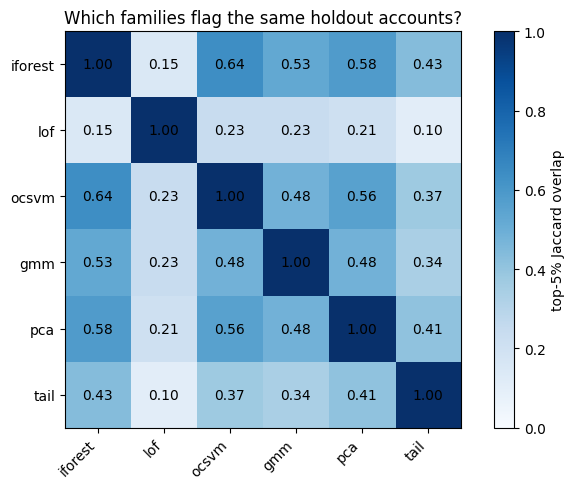

,family,original_engineered_top5_overlap,original_stability,engineered_stability
0,iforest,0.266,0.481,0.826
1,lof,0.208,0.860,0.826
2,ocsvm,0.533,0.970,0.980
3,gmm,0.471,0.961,0.970
4,pca,0.361,0.754,0.887
5,tail,0.356,0.951,0.942


Holdout alert volume: 192–227 / 4000 accounts
Least agreement: lof vs tail = 0.102 top-5% Jaccard
Original vs engineered overlap: 0.208–0.533
Security flags are model inputs; their prevalence among alerts is a behavior check, not validation.
No labels: stability and overlap cannot establish F3 or the best fraud detector.


In [25]:
primary_families = ["iforest", "lof", "ocsvm", "gmm", "pca", "tail"]
primary_names = {family: f"t5_r1_{family}_engineered_v1" for family in primary_families}

def top_set(scores, fraction=.05):
    k = max(1, round(len(scores)*fraction))
    return set(np.argpartition(scores, -k)[-k:])

def jaccard(a, b):
    return len(a & b)/len(a | b)

primary_tops = {family: top_set(score_cache[name]) for family, name in primary_names.items()}
agreement = pd.DataFrame(index=primary_families, columns=primary_families, dtype=float)
for a in primary_families:
    for b in primary_families:
        agreement.loc[a,b] = jaccard(primary_tops[a],primary_tops[b])
display(agreement.round(3))
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(agreement.to_numpy(dtype=float), vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(len(primary_families)), primary_families, rotation=45, ha="right")
ax.set_yticks(range(len(primary_families)), primary_families)
for i in range(len(primary_families)):
    for j in range(len(primary_families)):
        ax.text(j, i, f"{agreement.iloc[i,j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="top-5% Jaccard overlap")
ax.set_title("Which families flag the same holdout accounts?")
fig.tight_layout()
plt.show()

same_family = []
for family in primary_families:
    original = f"t5_r1_{family}_original_v1"
    engineered = primary_names[family]
    same_family.append({"family": family,
                        "original_engineered_top5_overlap": jaccard(top_set(score_cache[original]), top_set(score_cache[engineered])),
                        "original_stability": model_stats.set_index("name").loc[original,"rank_stability"],
                        "engineered_stability": model_stats.set_index("name").loc[engineered,"rank_stability"]})
same_family = pd.DataFrame(same_family)
display(same_family.round(3))

pairwise = agreement.where(~np.eye(len(agreement), dtype=bool)).stack()
least_pair = pairwise.idxmin()
print(f"Holdout alert volume: {model_stats.alerts.min()}–{model_stats.alerts.max()} / {len(hold_idx)} accounts")
print(f"Least agreement: {least_pair[0]} vs {least_pair[1]} = {pairwise.min():.3f} top-5% Jaccard")
print(f"Original vs engineered overlap: {same_family.original_engineered_top5_overlap.min():.3f}–{same_family.original_engineered_top5_overlap.max():.3f}")
print("Security flags are model inputs; their prevalence among alerts is a behavior check, not validation.")
print("No labels: stability and overlap cannot establish F3 or the best fraud detector.")
